# Spatiotemporal MJO V-JEPA — problem setup

A **Joint-Embedding Predictive Architecture (JEPA)** that learns a self-supervised
representation of the **Madden–Julian Oscillation (MJO)** from short sequences of daily
tropical anomaly maps, so that the per-day embeddings can be (a) clustered into MJO
**phases** and (b) used to classify MJO **propagation type** (standing / jumping /
slow / fast).

**Why JEPA rather than a reconstruction autoencoder (as in PhysAnchor)?**  The MJO is a
slowly *propagating* convective envelope.  A pixel-reconstruction loss forces the model
to reproduce every small-scale, largely unpredictable detail of OLR and wind.  JEPA
instead predicts **in latent space**: from the visible part of a clip it predicts the
*representation* of a hidden part (a masked longitude sector, or the next day).  Latent
prediction is translation-tolerant and discards unpredictable detail — a much better
fit for a propagating phenomenon, and it directly rewards encoding *where the envelope
is and where it is going*.

**Design (V-JEPA / I-JEPA recipe, adapted to the tropics):**

| piece | choice |
|---|---|
| sample | 3 consecutive days `(C=3 vars, T=3 days, 13 lat, 144 lon)` |
| variables | OLR, U850, U200 anomalies (WH04 definition, full 2-D maps) |
| encoder | spatiotemporal ViT, **periodic-longitude** 3-D positional embedding |
| target encoder | EMA copy of the encoder (stop-grad) |
| predictor | narrow ViT: context tokens + positioned mask tokens → target latents |
| masks | **spatial** contiguous-longitude sector (tube, wrap-around) + **temporal** future-day |
| loss | smooth-L1 / L2 in latent space (no pixel reconstruction) |

The spatial sector mask forces translation-tolerant zonal structure; the future-day
mask forces the model to learn the eastward propagation.

In [1]:
import os, sys
import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt

HERE = os.path.dirname(os.path.abspath("__file__")) if "__file__" not in globals() else os.path.dirname(os.path.abspath(__file__))
ROOT = os.path.dirname(HERE) if os.path.basename(HERE) == "jepa" else HERE
# notebook lives in .../MJO/jepa ; project root is .../MJO
ROOT = "/glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO"
sys.path.insert(0, ROOT)

from jepa.data.dataset import MJOSequence, SyntheticSequence
from jepa.masks.masking import build_mask_sampler
from jepa.models.encoder import build_encoder
from jepa.models.vjepa import build_vjepa
from jepa.models.pos_embed import get_1d_sincos_pos_embed_periodic

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
CFG = yaml.safe_load(open(os.path.join(ROOT, "jepa/config_vjepa.yaml")))
print("config sections:", list(CFG))

/glade/work/weidong/conda-envs/myenv/lib/python3.10/site-packages/pyramid/path.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


config sections: ['data', 'encoder', 'mask', 'method', 'train']


## 1. Configuration

All knobs live in `jepa/config_vjepa.yaml`; the training and downstream code read paths
and hyperparameters from there (no hardcoded paths in the logic).

In [2]:
D, E, M, TR = CFG["data"], CFG["encoder"], CFG["mask"], CFG["train"]
print(f"variables   : olr, u850, u200   (anomalies, WH04 definition, full 2-D maps)")
print(f"grid        : {E['img_size']} (lat x lon) @ 2.5deg, {D['lat_band']} band")
print(f"clip        : T={E['num_frames']} days, patch {E['patch_size']} (lat,lon)")
print(f"train years : {D['train_years']}   val years: {D['val_years']}  (split by anchor day)")
print(f"encoder     : dim={E['embed_dim']} depth={E['depth']} heads={E['num_heads']}")
print(f"mask        : mode={M['mode']} sector_width={M['sector_width']} n_future={M['n_future']}")
print(f"method      : pred_dim={CFG['method']['pred_dim']} loss={CFG['method']['loss_type']} "
      f"ema={CFG['method']['ema_momentum']}")

variables   : olr, u850, u200   (anomalies, WH04 definition, full 2-D maps)
grid        : [13, 144] (lat x lon) @ 2.5deg, [15.0, -15.0] band
clip        : T=3 days, patch [1, 8] (lat,lon)
train years : [1979, 2014]   val years: [2015, 2020]  (split by anchor day)
encoder     : dim=192 depth=6 heads=4
mask        : mode=mixed sector_width=[3, 6] n_future=1
method      : pred_dim=96 loss=smooth_l1 ema=[0.996, 1.0]


## 2. Data — daily 2-D anomaly maps, reusing the RMM anomaly definition

The anomaly pipeline is **identical to `0-compute_rmm.ipynb`**: for each grid point,
remove the seasonal cycle (mean + 3 annual harmonics, fit over the base period) and the
trailing-120-day mean; no bandpass.  The RMM notebook then meridionally averages to feed
the EOFs — here we **keep the full 2-D field** (`jepa/data/anomaly.py` ≡ the notebook's
§9 `to_anomaly`, applied to OLR, U850 and U200).

Run once if the cache is missing:
`python -m jepa.data.preprocess --config jepa/config_vjepa.yaml`

In [3]:
cache = D["cache_dir"]
have_cache = os.path.exists(os.path.join(cache, "anom.npy"))
if have_cache:
    anom = np.load(os.path.join(cache, "anom.npy"), mmap_mode="r")
    dates = np.load(os.path.join(cache, "dates.npy")).astype("datetime64[D]")
    stats = np.load(os.path.join(cache, "stats.npz"))
    print(f"anomaly cache: {anom.shape}  {dates[0]} -> {dates[-1]}")
    print(f"  lat {stats['lat'][0]:.1f}..{stats['lat'][-1]:.1f}  lon {stats['lon'][0]:.1f}..{stats['lon'][-1]:.1f}E")
    print(f"  per-var train mean {np.round(stats['mean'],3)}  std {np.round(stats['std'],3)}")
else:
    print("cache not found — run jepa/data/preprocess.py first.")

anomaly cache: (15222, 3, 13, 144)  1979-04-30 -> 2020-12-31
  lat 15.0..-15.0  lon 0.0..357.5E
  per-var train mean [-0.019  0.    -0.01 ]  std [29.566  3.468  7.414]


In [5]:
anom.shape

(15222, 3, 13, 144)

### A 3-day clip — one training sample

The model input is a short "video": three consecutive days of OLR/U850/U200 anomalies.
Below is one clip for a strong-MJO date (rows = variables, columns = days t-2, t-1, t).
Enhanced convection is **blue** (negative OLR anomaly) and should be seen drifting east
across the three days.

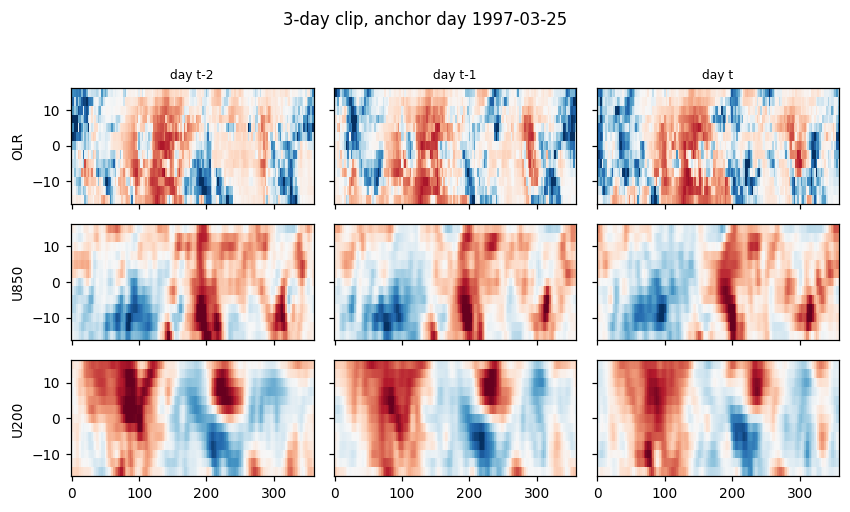

In [6]:
def draw_clip(clip, lat, lon, title=""):
    """clip: (C,T,H,W) standardized anomalies."""
    C, T, H, W = clip.shape
    names = ["OLR", "U850", "U200"]
    fig, axes = plt.subplots(C, T, figsize=(2.6*T, 1.5*C), sharex=True, sharey=True)
    for c in range(C):
        vmax = np.nanpercentile(np.abs(clip[c]), 99) or 1.0
        for t in range(T):
            ax = axes[c, t]
            ax.pcolormesh(lon, lat, clip[c, t], cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="nearest")
            if c == 0: ax.set_title(f"day t{['-2','-1',''][t]}", fontsize=8)
            if t == 0: ax.set_ylabel(names[c])
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

if have_cache:
    seq = MJOSequence(cache, list(range(D["year_start"], D["year_end"]+1)), seq_len=D["seq_len"])
    # pick a clip whose anchor date is a known strong-MJO day if rmm csv is present
    k = len(seq)//3
    try:
        import pandas as pd
        rmm = pd.read_csv(D["rmm_csv"], parse_dates=["time"])
        strong = rmm.loc[rmm["amplitude"].idxmax(), "time"]
        anchors = seq.anchor_dates()
        k = int(np.argmin(np.abs(anchors - np.datetime64(strong, "D"))))
    except Exception as e:
        print("(rmm pick skipped:", e, ")")
    s = seq[k]
    draw_clip(s["x"].numpy(), stats["lat"], stats["lon"],
              title=f"3-day clip, anchor day {seq.anchor_dates()[k]}")
else:
    print("cache not found — skipping clip plot")

In [8]:
rmm

,time,RMM1,RMM2,amplitude,phase
0,1979-04-30,-1.218483,-0.763776,1.438073,1
1,1979-05-01,-0.649611,-1.078586,1.259103,2
2,1979-05-02,-0.086459,-1.310581,1.313430,2
3,1979-05-03,0.343759,-1.226728,1.273983,3
4,1979-05-04,0.602215,-1.181197,1.325854,3
...,...,...,...,...,...
15217,2020-12-27,0.145534,-0.236478,0.277672,3
15218,2020-12-28,0.189418,-0.286174,0.343183,3
15219,2020-12-29,0.232989,-0.473572,0.527783,3
15220,2020-12-30,0.288442,-0.478217,0.558471,3


## 3. Masking — the two pretext tasks

**Spatial sector (tube) mask.** A contiguous block of longitude patch-columns, *wrapping*
across 0/360°, is hidden across all latitudes and all days.  The encoder sees the rest;
the predictor must reconstruct the hidden sector's latent — forcing translation-tolerant
zonal structure.

**Temporal future mask.** The last day is hidden entirely and predicted from the earlier
days — forcing the model to learn the eastward propagation.

The panels below show, on the patch grid `(T, lat, lon)`, which patches are **context**
(grey, 0) vs **target** (coloured, 1+).

patch grid (T, lat, lon) = (3, 13, 18)  tokens = 702


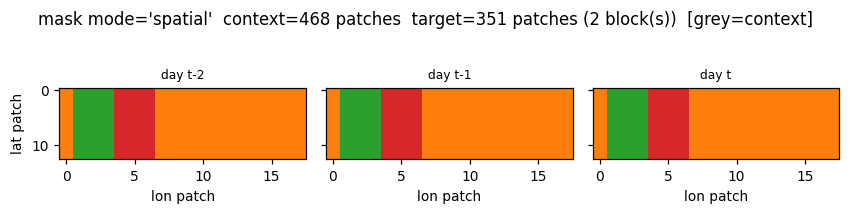

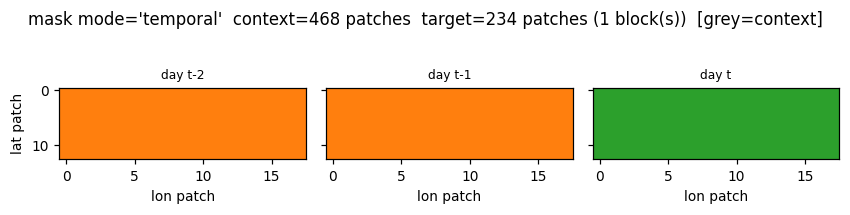

In [9]:
enc = build_encoder(E)
T, GH, GW = enc.grid_thw
print("patch grid (T, lat, lon) =", enc.grid_thw, " tokens =", enc.num_patches)

def show_mask(mode):
    ms = build_mask_sampler({**M, "mode": mode}, enc.grid_thw, seed=3)
    ctx, tgts = ms.sample()
    g = ms.role_grid(ctx, tgts)  # (T, GH, GW)
    fig, axes = plt.subplots(1, T, figsize=(2.6*T, 1.8), sharey=True)
    for t in range(T):
        axes[t].imshow(g[t], cmap="tab10", vmin=-1, vmax=8, aspect="auto", origin="upper")
        axes[t].set_title(f"day {['t-2','t-1','t'][t]}", fontsize=8)
        axes[t].set_xlabel("lon patch");
    axes[0].set_ylabel("lat patch")
    n_t = sum(len(x) for x in tgts)
    fig.suptitle(f"mask mode='{mode}'  context={len(ctx)} patches  target={n_t} patches "
                 f"({len(tgts)} block(s))  [grey=context]", y=1.05)
    plt.tight_layout(); plt.show()

for mode in ["spatial", "temporal"]:
    show_mask(mode)

### Periodic longitude positional embedding

Longitude is a full 0–360° circle, so the positional embedding must wrap (patch column
`W` ≡ column `0`).  We use a **low-pass periodic** embedding — integer harmonics of
`2π/W` with decaying amplitude — so the distance between two longitude codes grows
smoothly with their angular separation and is symmetric across the 0/360° seam (the
antipode is farthest, the two seam-neighbours are equidistant).

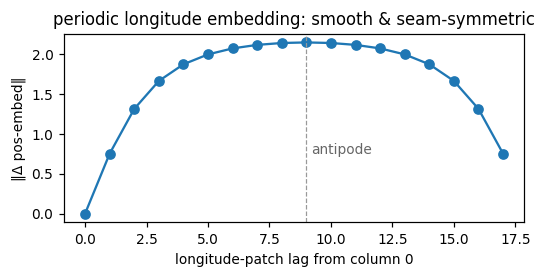

seam symmetry: d(0,1)=0.751 vs d(0,W-1)=0.751  |  neighbour<antipode: True


In [10]:
W = enc.grid_thw[2]
pe = get_1d_sincos_pos_embed_periodic(72, W)
d = [np.linalg.norm(pe[0]-pe[j]) for j in range(W)]
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(range(W), d, "o-")
ax.set(xlabel="longitude-patch lag from column 0", ylabel="‖Δ pos-embed‖",
       title="periodic longitude embedding: smooth & seam-symmetric")
ax.axvline(W/2, color="0.6", ls="--", lw=0.8); ax.text(W/2+0.2, d[1], "antipode", color="0.4")
plt.tight_layout(); plt.show()
print(f"seam symmetry: d(0,1)={d[1]:.3f} vs d(0,W-1)={d[W-1]:.3f}  |  neighbour<antipode: {d[1]<d[W//2]}")

## 4. Architecture summary

Context encoder, EMA target encoder, and the narrow predictor — built straight from the
config.  A single forward pass returns the latent-space loss and the collapse monitor
(target-embedding std; a collapsed encoder would drive this toward 0).

In [11]:
ms = build_mask_sampler(M, enc.grid_thw, seed=0)
model = build_vjepa(enc, ms, CFG["method"])
def nparams(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"context encoder : {nparams(model.context_encoder)/1e6:.2f} M")
print(f"predictor       : {nparams(model.predictor)/1e6:.2f} M")
print(f"target encoder  : EMA copy (frozen), momentum {CFG['method']['ema_momentum']}")
print(f"total trainable : {nparams(model)/1e6:.2f} M")

# one forward pass on a real (or synthetic) batch
if have_cache:
    xb = torch.stack([seq[i]["x"] for i in range(8)])
else:
    sy = SyntheticSequence(n=8, shape=(E["in_chans"], E["num_frames"], *E["img_size"]))
    xb = torch.stack([sy[i]["x"] for i in range(8)])
loss, st = model(xb)
print(f"\nforward: loss={st['loss']:.4f}  pred_loss={st['pred_loss']:.4f}  "
      f"tgt_std={st['tgt_std']:.3f} (collapse monitor; >0 is healthy)  "
      f"ctx={st['n_ctx']} tgt={st['n_tgt']} tokens")

context encoder : 2.67 M
predictor       : 0.48 M
target encoder  : EMA copy (frozen), momentum [0.996, 1.0]
total trainable : 3.16 M

forward: loss=0.5282  pred_loss=0.5282  tgt_std=0.400 (collapse monitor; >0 is healthy)  ctx=468 tgt=234 tokens


## 5. How to train and use

```bash
cd /glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO

# 0. one-time anomaly cache (needs xarray; ~2-3 GB)
python -m jepa.data.preprocess --config jepa/config_vjepa.yaml

# 1. quick CPU smoke test (synthetic propagating clips; asserts loss falls, no collapse)
python jepa/train_vjepa.py --config jepa/config_vjepa.yaml --smoke

# 2. single-GPU pretraining (AMP, EMA, cosine LR, checkpoints best/last, resume)
python jepa/train_vjepa.py --config jepa/config_vjepa.yaml

# 3. downstream
python -m jepa.downstream.extract     --ckpt runs/vjepa/best.tar   # daily embeddings
python -m jepa.downstream.cluster     --ckpt runs/vjepa/best.tar   # SOM/k-means phases + RMM agreement
python -m jepa.downstream.propagation --ckpt runs/vjepa/best.tar   # standing/jumping/slow/fast head
```

**Assumptions (this setup):** 2.5° grid, 15°N–15°S band (13 lat × 144 lon), full periodic
longitude; OLR/U850/U200 WH04 anomalies (seasonal harmonics + 120-day mean, no bandpass),
per-variable standardized on the training years; clips of 3 consecutive days; train
1979–2014 / val 2015–2020 split by anchor day; spatial sector + future-day masking; latent
smooth-L1 loss with an EMA target encoder.